# Project 1: NYC Yellow Taxi Data Detective
**CS672 — Fall 2026 | Due October 16, 2026**

Name: **Negar Kamvij**

This is a starter notebook. Run cells in order and replace the writing prompts with your own findings. No analysis has been run yet.

## Our question
Which features are related to how long a taxi ride takes?

Think of each row as a little information card for one ride. We will inspect the cards, find mistakes, draw charts, and explain what we learned. We do not need to train a model.

- March 2020: training dataset.
- May 2020: evaluation dataset.
- January 2020: optional extra credit.

## 1. Set up your tools
Use a Python environment compatible with TensorFlow Data Validation (TFDV). Check its official installation guide before installing; package compatibility varies by environment:
https://www.tensorflow.org/tfx/data_validation/install

The assignment requires TFDV, Apache Beam, and GraphViz. GraphViz is also a system application; installing a Python wrapper alone does not install it. Install dependencies in a dedicated environment rather than an unrelated project.


In [ ]:
# Run this in your chosen notebook environment.
%pip install pandas numpy matplotlib seaborn pyarrow tensorflow-data-validation "apache-beam[interactive]" graphviz

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("sample_data/data")
DATA_DIR.mkdir(exist_ok=True)


## 2. Get the taxi information cards
Download **Yellow Taxi** March 2020 and May 2020 Parquet files from the official NYC TLC page and put them in the `data` folder beside this notebook:
https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

Expected filenames: `yellow_tripdata_2020-03.parquet` and `yellow_tripdata_2020-05.parquet`.

Taxi files can be large. Start with one month if memory is limited, and clearly document any sampling you use.


In [17]:
paths = {"March": DATA_DIR / "yellow_tripdata_2020-03.parquet",
         "May": DATA_DIR / "yellow_tripdata_2020-05.parquet"}
missing = [str(path) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError("Download these files first: " + ", ".join(missing))
raw = {month: pd.read_parquet(path) for month, path in paths.items()}
display(raw["March"].head())


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,1,2020-03-01 00:31:13,2020-03-01 01:01:42,1.0,4.70,1.0,N,88,255,1,22.0,3.0,0.5,2.00,0.0,0.3,27.80,2.5,None
1,2,2020-03-01 00:08:22,2020-03-01 00:08:49,1.0,0.00,1.0,N,193,193,2,2.5,0.5,0.5,0.00,0.0,0.3,3.80,0.0,None
2,1,2020-03-01 00:52:18,2020-03-01 00:59:16,1.0,1.10,1.0,N,246,90,1,6.0,3.0,0.5,1.95,0.0,0.3,11.75,2.5,None
3,2,2020-03-01 00:47:53,2020-03-01 00:50:57,2.0,0.87,1.0,N,151,238,1,5.0,0.5,0.5,1.76,0.0,0.3,10.56,2.5,None
4,1,2020-03-01 00:43:19,2020-03-01 00:58:27,0.0,4.40,1.0,N,79,261,1,16.5,3.0,0.5,4.05,0.0,0.3,24.35,2.5,None


## 3. Look before cleaning
Count rows, identify data types, and find missing values. A numeric code can represent a category: payment type and location IDs are examples. Record both the stored type and its meaning.

In [18]:
for month, frame in raw.items():
    print(month, "rows:", len(frame), "columns:", len(frame.columns))
    display(pd.DataFrame({"stored_type": frame.dtypes.astype(str),
                          "missing_count": frame.isna().sum(),
                          "missing_percent": frame.isna().mean() * 100}))
    display(frame.describe(include="all").T)
    print("Exact duplicate rows:", frame.duplicated().sum())


March rows: 3007687 columns: 19


,stored_type,missing_count,missing_percent
VendorID,int64,0,0.000000
tpep_pickup_datetime,datetime64[us],0,0.000000
tpep_dropoff_datetime,datetime64[us],0,0.000000
passenger_count,float64,37808,1.257046
trip_distance,float64,0,0.000000
RatecodeID,float64,37808,1.257046
store_and_fwd_flag,object,37808,1.257046
PULocationID,int64,0,0.000000
DOLocationID,int64,0,0.000000
payment_type,int64,0,0.000000


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
VendorID,3007687.0,NaN,NaN,NaN,1.671989,1.0,1.0,2.0,2.0,6.0,0.472886
tpep_pickup_datetime,3007687,NaN,NaN,NaN,2020-03-09 01:48:50.541679,2008-12-31 23:02:19,2020-03-04 18:26:35,2020-03-07 22:31:41,2020-03-12 08:23:20,2020-08-27 15:16:15,NaN
tpep_dropoff_datetime,3007687,NaN,NaN,NaN,2020-03-09 02:04:25.845666,2008-12-31 23:35:21,2020-03-04 18:43:22,2020-03-07 22:46:40,2020-03-12 08:39:24,2020-08-27 15:21:14,NaN
passenger_count,2969879.0,NaN,NaN,NaN,1.467477,0.0,1.0,1.0,1.0,9.0,1.120087
trip_distance,3007687.0,NaN,NaN,NaN,3.117041,0.0,1.0,1.67,3.02,269803.73,206.920728
RatecodeID,2969879.0,NaN,NaN,NaN,1.051377,1.0,1.0,1.0,1.0,99.0,0.710921
store_and_fwd_flag,2969879,2,N,2941898,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PULocationID,3007687.0,NaN,NaN,NaN,163.429781,1.0,114.0,162.0,234.0,265.0,66.586537
DOLocationID,3007687.0,NaN,NaN,NaN,160.933627,1.0,107.0,162.0,234.0,265.0,70.741316
payment_type,3007687.0,NaN,NaN,NaN,1.251811,0.0,1.0,1.0,2.0,4.0,0.49412


Exact duplicate rows: 0
May rows: 348415 columns: 19


,stored_type,missing_count,missing_percent
VendorID,int64,0,0.000000
tpep_pickup_datetime,datetime64[us],0,0.000000
tpep_dropoff_datetime,datetime64[us],0,0.000000
passenger_count,float64,58901,16.905415
trip_distance,float64,0,0.000000
RatecodeID,float64,58901,16.905415
store_and_fwd_flag,object,58901,16.905415
PULocationID,int64,0,0.000000
DOLocationID,int64,0,0.000000
payment_type,int64,0,0.000000


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
VendorID,348415.0,NaN,NaN,NaN,1.630091,1.0,1.0,2.0,2.0,6.0,0.484691
tpep_pickup_datetime,348415,NaN,NaN,NaN,2020-05-16 21:47:01.946934,2008-12-31 23:05:47,2020-05-09 07:18:24,2020-05-16 17:19:02,2020-05-24 16:28:31,2020-11-01 15:41:04,NaN
tpep_dropoff_datetime,348415,NaN,NaN,NaN,2020-05-16 22:00:32.603673,2008-12-31 23:33:33,2020-05-09 07:34:38.500000,2020-05-16 17:31:49,2020-05-24 16:42:16.500000,2020-11-01 15:57:02,NaN
passenger_count,289514.0,NaN,NaN,NaN,1.314171,0.0,1.0,1.0,1.0,9.0,0.983983
trip_distance,348415.0,NaN,NaN,NaN,8.333053,0.0,1.05,1.99,4.25,297004.51,774.817906
RatecodeID,289514.0,NaN,NaN,NaN,1.043062,1.0,1.0,1.0,1.0,99.0,0.96945
store_and_fwd_flag,289514,2,N,286687,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PULocationID,348415.0,NaN,NaN,NaN,152.597822,1.0,90.0,143.0,231.0,265.0,70.864142
DOLocationID,348415.0,NaN,NaN,NaN,148.483274,1.0,75.0,143.0,230.0,265.0,74.815894
payment_type,348415.0,NaN,NaN,NaN,1.182598,0.0,1.0,1.0,2.0,4.0,0.734705


Exact duplicate rows: 0


In [19]:
for month, frame in raw.items():
    print("\n==========", month.upper(), "==========")
    print("Number of rides:", len(frame))
    print("Number of columns:", len(frame.columns))

    print("\nMissing values:")
    missing_summary = frame.isna().sum()
    print(missing_summary[missing_summary > 0].sort_values(ascending=False))

    print("\nPickup date range:")
    print("Earliest:", frame["tpep_pickup_datetime"].min())
    print("Latest:  ", frame["tpep_pickup_datetime"].max())

    print("\nTrip distance:")
    print(frame["trip_distance"].describe())

    print("\nPassenger count:")
    print(frame["passenger_count"].describe())

    print("\nExact duplicates:", frame.duplicated().sum())


========== MARCH ==========
Number of rides: 3007687
Number of columns: 19

Missing values:
airport_fee             3007687
passenger_count           37808
RatecodeID                37808
store_and_fwd_flag        37808
congestion_surcharge      37808
dtype: int64

Pickup date range:
Earliest: 2008-12-31 23:02:19
Latest:   2020-08-27 15:16:15

Trip distance:
count    3.007687e+06
mean     3.117041e+00
std      2.069207e+02
min      0.000000e+00
25%      1.000000e+00
50%      1.670000e+00
75%      3.020000e+00
max      2.698037e+05
Name: trip_distance, dtype: float64

Passenger count:
count    2.969879e+06
mean     1.467477e+00
std      1.120087e+00
min      0.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      9.000000e+00
Name: passenger_count, dtype: float64

Exact duplicates: 0

========== MAY ==========
Number of rides: 348415
Number of columns: 19

Missing values:
airport_fee             348415
passenger_count          58901
RatecodeID           

**Your notes:** List numeric, categorical, and datetime features. Explain missing values and whether apparent duplicates really should be removed.

## 4. Calculate ride duration and inspect unusual rides
Duration is drop-off time minus pickup time, in minutes. Inspect extreme values before deciding what to remove. Negative or zero duration cannot represent a positive-duration ride. Very long rides might be real or might be errors.


In [20]:
def add_duration(frame):
    result = frame.copy()
    for col in ["tpep_pickup_datetime", "tpep_dropoff_datetime"]:
        result[col] = pd.to_datetime(result[col], errors="coerce")
    result["trip_duration_minutes"] = (
        result["tpep_dropoff_datetime"] - result["tpep_pickup_datetime"]
    ).dt.total_seconds() / 60
    return result

prepared = {month: add_duration(frame) for month, frame in raw.items()}
for month, frame in prepared.items():
    print(month)
    display(frame[["trip_duration_minutes", "trip_distance"]].describe(
        percentiles=[.01, .5, .95, .99]))
    display(frame.nlargest(5, "trip_duration_minutes"))


March


,trip_duration_minutes,trip_distance
count,3.007687e+06,3.007687e+06
mean,1.558840e+01,3.117041e+00
std,6.558050e+01,2.069207e+02
min,-4.746262e+04,0.000000e+00
1%,9.000000e-01,0.000000e+00
50%,1.040000e+01,1.670000e+00
95%,3.276667e+01,1.023000e+01
99%,5.436667e+01,1.888000e+01
max,1.814817e+03,2.698037e+05


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration_minutes
903843,2,2020-03-05 12:46:56,2020-03-06 19:01:45,3.0,0.64,1.0,N,238,263,2,5.0,1.0,0.5,0.00,0.0,0.3,9.30,2.5,None,1814.816667
904339,2,2020-03-05 12:46:56,2020-03-06 18:57:23,1.0,2.90,1.0,N,238,142,2,45.0,0.0,0.5,0.00,0.0,0.3,48.30,2.5,None,1810.450000
2634594,2,2020-03-15 15:06:30,2020-03-16 15:06:29,1.0,0.00,1.0,N,152,166,2,2.5,0.0,0.5,0.00,0.0,0.3,5.80,0.0,None,1439.983333
1234714,2,2020-03-06 18:49:43,2020-03-07 18:49:39,2.0,0.86,1.0,N,161,186,1,8.0,1.0,0.5,1.23,0.0,0.3,13.53,2.5,None,1439.933333
666728,2,2020-03-04 12:06:54,2020-03-05 12:06:40,1.0,3.08,1.0,N,48,43,2,13.5,0.0,0.5,0.00,0.0,0.3,16.80,2.5,None,1439.766667


May


,trip_duration_minutes,trip_distance
count,348415.000000,348415.000000
mean,13.510946,8.333053
std,47.169801,774.817906
min,-0.333333,0.000000
1%,0.366667,0.000000
50%,8.950000,1.990000
95%,32.000000,13.500000
99%,47.000000,21.110000
max,1438.866667,297004.510000


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration_minutes
14176,2,2020-05-02 15:48:31,2020-05-03 15:47:23,1.0,5.02,1.0,N,68,41,2,18.5,0.0,0.5,0.0,0.0,0.3,21.8,2.5,None,1438.866667
196701,2,2020-05-22 16:49:41,2020-05-23 16:48:11,1.0,1.48,1.0,N,116,41,1,8.5,1.0,0.5,0.0,0.0,0.3,10.3,0.0,None,1438.500000
281667,2,2020-05-31 00:15:01,2020-06-01 00:13:30,1.0,3.05,1.0,N,37,97,2,12.0,0.5,0.5,0.0,0.0,0.3,13.3,0.0,None,1438.483333
135500,2,2020-05-16 15:11:34,2020-05-17 15:09:57,1.0,1.42,1.0,N,143,48,1,8.0,0.0,0.5,1.7,0.0,0.3,13.0,2.5,None,1438.383333
6471,2,2020-05-01 15:50:41,2020-05-02 15:49:00,1.0,0.00,1.0,N,193,193,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,None,1438.316667


## 5. Clean using explicit rules
The rules below are a starting point: require valid timestamps, a positive duration, a nonnegative known distance, and pickup within the intended month. Zero-distance trips are retained for investigation. Duplicate removal and upper outlier cutoffs need justification before adding them.

Apply the same rules to both months. Keep a count of removed rows. Do not silently drop every row with any missing value.


In [21]:
def clean_month(frame, month_number):
    result = frame.copy()
    rules = {
        "valid timestamps": result["tpep_pickup_datetime"].notna() & result["tpep_dropoff_datetime"].notna(),
        "positive finite duration": np.isfinite(result["trip_duration_minutes"]) & result["trip_duration_minutes"].gt(0),
        "known nonnegative finite distance": np.isfinite(result["trip_distance"]) & result["trip_distance"].ge(0),
        "pickup in intended month": result["tpep_pickup_datetime"].dt.year.eq(2020) & result["tpep_pickup_datetime"].dt.month.eq(month_number),
    }
    keep = pd.Series(True, index=result.index)
    audit = []
    for name, valid in rules.items():
        before = int(keep.sum())
        keep &= valid
        audit.append({"rule": name, "removed_at_this_step": before - int(keep.sum()), "remaining": int(keep.sum())})
    result = result.loc[keep].copy()
    result["pickup_hour"] = result["tpep_pickup_datetime"].dt.hour
    result["pickup_day_of_week"] = result["tpep_pickup_datetime"].dt.dayofweek
    return result, pd.DataFrame(audit)

clean = {}
for month, number in [("March", 3), ("May", 5)]:
    clean[month], audit = clean_month(prepared[month], number)
    print(month)
    display(audit)


March


,rule,removed_at_this_step,remaining
0,valid timestamps,0,3007687
1,positive finite duration,2131,3005556
2,known nonnegative finite distance,0,3005556
3,pickup in intended month,426,3005130


May


,rule,removed_at_this_step,remaining
0,valid timestamps,0,348415
1,positive finite duration,630,347785
2,known nonnegative finite distance,0,347785
3,pickup in intended month,23,347762


In [24]:
# Investigate possible outliers before deciding whether to remove them

for month, frame in clean.items():
    print("\n==========", month.upper(), "==========")

    print("\nTrip duration (minutes):")
    print(
        frame["trip_duration_minutes"].quantile(
            [0.50, 0.90, 0.95, 0.99, 0.999, 1.00]
        )
    )

    print("\nTrip distance (miles):")
    print(
        frame["trip_distance"].quantile(
            [0.50, 0.90, 0.95, 0.99, 0.999, 1.00]
        )
    )


========== MARCH ==========

Trip duration (minutes):
0.500      10.400000
0.900      25.550000
0.950      32.783333
0.990      54.366667
0.999    1412.564517
1.000    1814.816667
Name: trip_duration_minutes, dtype: float64

Trip distance (miles):
0.500         1.67
0.900         6.47
0.950        10.23
0.990        18.88
0.999        27.08
1.000    269803.73
Name: trip_distance, dtype: float64

========== MAY ==========

Trip duration (minutes):
0.500       8.966667
0.900      25.233333
0.950      32.000000
0.990      47.000000
0.999    1330.615417
1.000    1438.866667
Name: trip_duration_minutes, dtype: float64

Trip distance (miles):
0.500         2.00
0.900         9.45
0.950        13.50
0.990        21.12
0.999        36.17
1.000    297004.51
Name: trip_distance, dtype: float64


In [25]:
for month, frame in clean.items():
    print("\n==========", month.upper(), "==========")

    print("\nLongest 10 trips by duration:")
    display(
        frame.nlargest(10, "trip_duration_minutes")[
            [
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
                "trip_duration_minutes",
                "trip_distance",
                "fare_amount",
                "total_amount"
            ]
        ]
    )

    print("\nLongest 10 trips by distance:")
    display(
        frame.nlargest(10, "trip_distance")[
            [
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
                "trip_duration_minutes",
                "trip_distance",
                "fare_amount",
                "total_amount"
            ]
        ]
    )


========== MARCH ==========

Longest 10 trips by duration:


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount
903843,2020-03-05 12:46:56,2020-03-06 19:01:45,1814.816667,0.64,5.0,9.30
904339,2020-03-05 12:46:56,2020-03-06 18:57:23,1810.450000,2.90,45.0,48.30
2634594,2020-03-15 15:06:30,2020-03-16 15:06:29,1439.983333,0.00,2.5,5.80
1234714,2020-03-06 18:49:43,2020-03-07 18:49:39,1439.933333,0.86,8.0,13.53
666728,2020-03-04 12:06:54,2020-03-05 12:06:40,1439.766667,3.08,13.5,16.80
808515,2020-03-04 21:54:58,2020-03-05 21:54:44,1439.766667,35.29,117.0,148.98
531661,2020-03-03 18:30:45,2020-03-04 18:30:27,1439.700000,1.30,9.5,13.80
2861436,2020-03-21 12:10:16,2020-03-22 12:09:58,1439.700000,0.00,-2.5,-3.30
2861437,2020-03-21 12:10:16,2020-03-22 12:09:58,1439.700000,0.00,2.5,3.30
1706546,2020-03-09 08:40:20,2020-03-10 08:40:01,1439.683333,1.91,14.0,17.30



Longest 10 trips by distance:


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount
2973275,2020-03-03 04:23:00,2020-03-03 04:39:00,16.00,269803.73,17.90,18.70
2978212,2020-03-05 08:09:00,2020-03-05 09:55:00,106.00,210148.62,40.54,47.46
2984809,2020-03-09 07:08:00,2020-03-09 07:31:00,23.00,70137.72,13.01,19.89
3003085,2020-03-20 12:34:00,2020-03-20 13:27:00,53.00,68704.94,11.02,11.82
2970356,2020-03-01 10:48:00,2020-03-01 11:20:00,32.00,34325.10,40.33,50.00
3001015,2020-03-18 07:52:00,2020-03-18 08:21:00,29.00,27620.85,11.54,12.34
2986745,2020-03-10 05:50:00,2020-03-10 06:35:00,45.00,14099.31,49.94,50.74
2981730,2020-03-07 00:33:00,2020-03-07 00:39:00,6.00,2193.72,13.95,14.75
2744264,2020-03-17 13:38:51,2020-03-17 19:36:51,358.00,310.90,804.00,1023.67
2935972,2020-03-27 17:15:34,2020-03-27 21:45:01,269.45,233.69,350.00,352.80



========== MAY ==========

Longest 10 trips by duration:


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount
14176,2020-05-02 15:48:31,2020-05-03 15:47:23,1438.866667,5.02,18.5,21.80
196701,2020-05-22 16:49:41,2020-05-23 16:48:11,1438.500000,1.48,8.5,10.30
281667,2020-05-31 00:15:01,2020-06-01 00:13:30,1438.483333,3.05,12.0,13.30
135500,2020-05-16 15:11:34,2020-05-17 15:09:57,1438.383333,1.42,8.0,13.00
6471,2020-05-01 15:50:41,2020-05-02 15:49:00,1438.316667,0.00,0.0,0.00
96017,2020-05-12 13:28:47,2020-05-13 13:27:06,1438.316667,0.00,0.0,0.00
181402,2020-05-21 11:30:54,2020-05-22 11:29:09,1438.250000,0.00,0.0,0.00
155447,2020-05-19 02:44:16,2020-05-20 02:42:29,1438.216667,14.49,42.0,45.80
101944,2020-05-13 08:08:05,2020-05-14 08:06:14,1438.150000,10.04,29.0,40.38
255124,2020-05-28 17:56:29,2020-05-29 17:54:36,1438.116667,4.46,14.5,22.56



Longest 10 trips by distance:


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,total_amount
291788,2020-05-02 06:06:00,2020-05-02 06:33:00,27.0,297004.51,32.34,35.64
310208,2020-05-11 08:12:00,2020-05-11 08:44:00,32.0,148342.26,53.58,54.38
328045,2020-05-17 04:26:00,2020-05-17 06:27:00,121.0,130587.13,29.91,30.71
306487,2020-05-09 05:12:00,2020-05-09 05:32:00,20.0,128870.92,28.03,28.83
297584,2020-05-05 18:48:00,2020-05-05 19:15:00,27.0,127377.15,10.43,13.98
343879,2020-05-28 06:01:00,2020-05-28 07:19:00,78.0,120206.70,16.75,17.55
326713,2020-05-16 08:08:00,2020-05-16 08:25:00,17.0,95650.01,8.00,11.55
312915,2020-05-12 06:17:00,2020-05-12 06:44:00,27.0,68064.12,21.27,24.57
320622,2020-05-14 14:26:00,2020-05-14 15:06:00,40.0,50992.70,14.85,18.15
343933,2020-05-28 07:51:00,2020-05-28 08:31:00,40.0,50911.51,30.77,41.69


In [26]:
for month, frame in clean.items():
    bad_duration = (
        (frame["trip_duration_minutes"] > 180)
    ).sum()

    bad_distance = (
        (frame["trip_distance"] <= 0) |
        (frame["trip_distance"] > 100)
    ).sum()

    bad_either = (
        (frame["trip_duration_minutes"] > 180) |
        (frame["trip_distance"] <= 0) |
        (frame["trip_distance"] > 100)
    ).sum()

    print(f"\n{month}")
    print("Duration > 180 minutes:", bad_duration)
    print("Distance <= 0 or > 100 miles:", bad_distance)
    print("Rows failing either rule:", bad_either)
    print(
        "Percent of dataset:",
        round(bad_either / len(frame) * 100, 3),
        "%"
    )


March
Duration > 180 minutes: 5884
Distance <= 0 or > 100 miles: 29539
Rows failing either rule: 35349
Percent of dataset: 1.176 %

May
Duration > 180 minutes: 462
Distance <= 0 or > 100 miles: 9748
Rows failing either rule: 10190
Percent of dataset: 2.93 %


In [27]:
# Create the final pristine dataset after removing implausible outliers

pristine = {}

for month, frame in clean.items():

    valid = (
        (frame["trip_duration_minutes"] <= 180)
        & (frame["trip_distance"] > 0)
        & (frame["trip_distance"] <= 100)
    )

    pristine[month] = frame.loc[valid].copy()

    removed = len(frame) - len(pristine[month])

    print(f"\n{month}")
    print("Before outlier cleaning:", len(frame))
    print("Removed:", removed)
    print("Final pristine rows:", len(pristine[month]))
    print(
        "Percent removed:",
        round(removed / len(frame) * 100, 3),
        "%"
    )


March
Before outlier cleaning: 3005130
Removed: 35349
Final pristine rows: 2969781
Percent removed: 1.176 %

May
Before outlier cleaning: 347762
Removed: 10190
Final pristine rows: 337572
Percent removed: 2.93 %


## 6. Explore with pictures
For each picture, write what you see and what it might mean. Correlation is an association, not proof that one feature causes another.

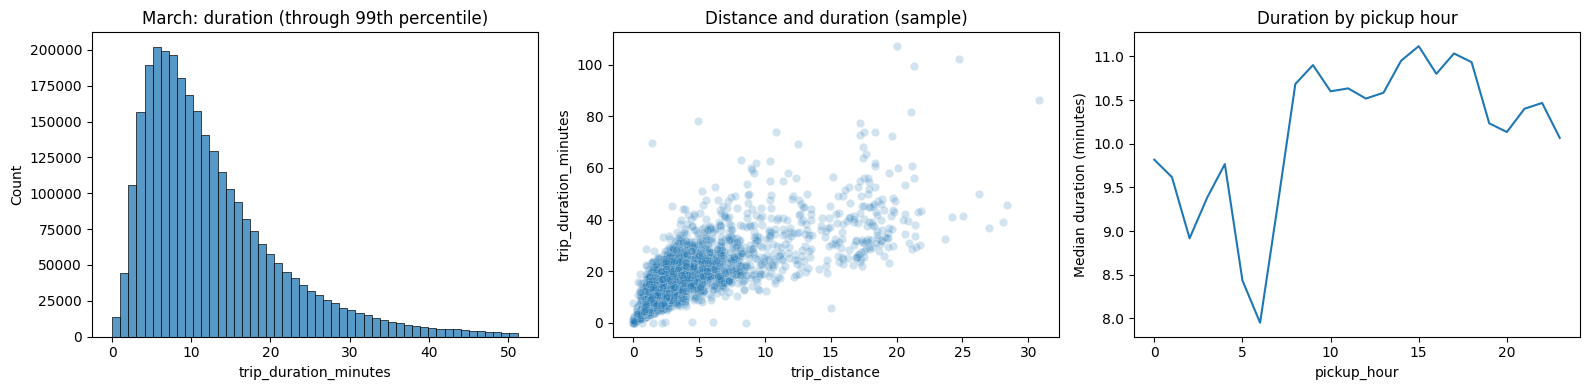

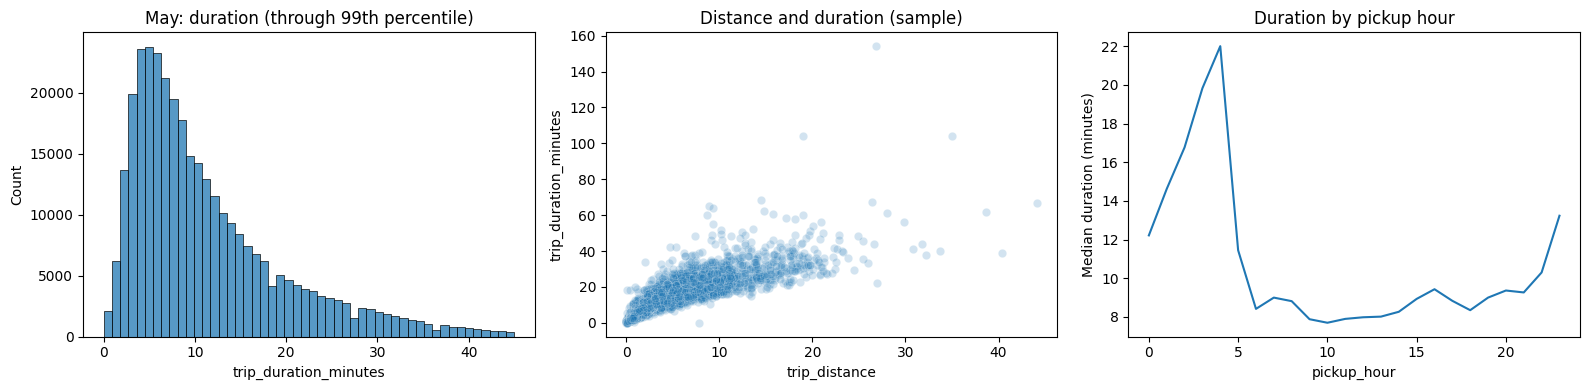

,trip_distance,passenger_count,pickup_hour,pickup_day_of_week,trip_duration_minutes
trip_distance,1.000000,0.016847,0.024930,0.011917,0.858601
passenger_count,0.016847,1.000000,0.033201,0.044761,0.019968
pickup_hour,0.024930,0.033201,1.000000,-0.039621,0.029772
pickup_day_of_week,0.011917,0.044761,-0.039621,1.000000,-0.045061
trip_duration_minutes,0.858601,0.019968,0.029772,-0.045061,1.000000


In [29]:
for month, frame in pristine.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    # Limit the displayed range only; this does not remove rows from the data.
    upper = frame["trip_duration_minutes"].quantile(.99)
    sns.histplot(frame.loc[frame["trip_duration_minutes"].le(upper), "trip_duration_minutes"], bins=50, ax=axes[0])
    axes[0].set_title(f"{month}: duration (through 99th percentile)")
    sample = frame.sample(n=min(5000, len(frame)), random_state=42)
    sns.scatterplot(data=sample, x="trip_distance", y="trip_duration_minutes", alpha=.2, ax=axes[1])
    axes[1].set_title("Distance and duration (sample)")
    frame.groupby("pickup_hour")["trip_duration_minutes"].median().plot(ax=axes[2])
    axes[2].set_ylabel("Median duration (minutes)")
    axes[2].set_title("Duration by pickup hour")
    plt.tight_layout()
    plt.show()

columns = ["trip_distance", "passenger_count", "pickup_hour", "pickup_day_of_week", "trip_duration_minutes"]
display(pristine["March"][columns].corr(method="spearman"))


**Your findings:** After cleaning the data and removing the unrealistic outliers, the patterns in the data are more clear. For both March and May, most of the taxi trips have shorter duration, and there are less trips with very long duration.
Trip distance has the strongest relationship with trip duration. In March, the Spearman correlation between trip distance and trip duration is about 0.86, which is a strong positive correlation. We can also see this in the scatterplots. When the trip distance increases, usually the trip duration also increases. So, trip distance seems to be one of the most important features for predicting the duration of a taxi trip.
The other features have much weaker correlations with trip duration. Passenger count has a correlation of about 0.02, pickup hour is about 0.03, and pickup day of week is about -0.05. Based on these numbers, passenger count and day of week do not show a strong relationship with trip duration.
However, pickup hour is interesting. Even though its correlation is very small, the graphs show that the median trip duration changes during different hours of the day. In March, some early morning hours have shorter trips, while the duration becomes higher during some daytime and afternoon hours. May has a different pattern, especially during very early morning hours where the median duration is much higher. This means that only looking at the correlation number may not show the complete relationship.
Overall, trip distance is the strongest feature related to trip duration in this analysis. Pickup hour may also be useful because the duration changes depending on the time of the day. Passenger count and day of week seem to have much weaker relationships with trip duration. This analysis also shows why it is important to look at both the graphs and correlation values when doing EDA..

## 7. Compare March and May
COVID affected this period. Describe observed differences without claiming this comparison alone proves their cause.


,cleaned_trip_count,median_duration_minutes,median_distance,missing_passenger_count_percent
March,2969781.0,10.416667,1.69,1.261911
May,337572.0,8.933333,2.05,17.075765


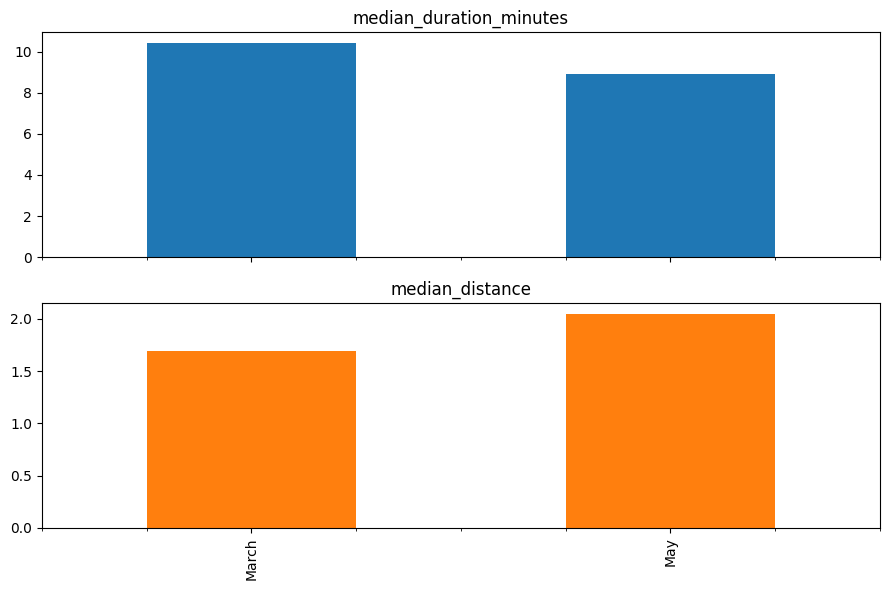

In [30]:
comparison = pd.DataFrame({month: {
    "cleaned_trip_count": len(frame),
    "median_duration_minutes": frame["trip_duration_minutes"].median(),
    "median_distance": frame["trip_distance"].median(),
    "missing_passenger_count_percent": frame["passenger_count"].isna().mean() * 100,
} for month, frame in pristine.items()}).T
display(comparison)
comparison[["median_duration_minutes", "median_distance"]].plot.bar(subplots=True, figsize=(9, 6), legend=False)
plt.tight_layout()
plt.show()


## 8. Use TensorFlow Data Validation (required)
Generate graphical statistics for both months. Infer the schema from March and check May against it. Review detected anomalies; an anomaly is something to investigate, not automatic permission to delete data.

These cells require a working TFDV installation. They have not been executed in this starter notebook.


In [32]:
%pip install -q tensorflow-data-validation

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.9/99.9 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.3/52.3 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.8/88.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.3/19.3 MB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.4/54.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.2/135.2 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 575.8/575.8 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━

In [33]:
import tensorflow_data_validation as tfdv

print("TFDV version:", tfdv.__version__)

TFDV version: 1.21.0


In [37]:
import tensorflow_data_validation as tfdv

# Use a focused set of columns to start. Expand for your final analysis.
validation_columns = ["trip_distance", "passenger_count", "pickup_hour", "pickup_day_of_week", "trip_duration_minutes"]
train_stats = tfdv.generate_statistics_from_dataframe(pristine["March"][validation_columns])
eval_stats = tfdv.generate_statistics_from_dataframe(pristine["May"][validation_columns])
tfdv.visualize_statistics(train_stats, eval_stats, lhs_name="March", rhs_name="May")
schema = tfdv.infer_schema(train_stats)
tfdv.display_schema(schema)
anomalies = tfdv.validate_statistics(eval_stats, schema)
tfdv.display_anomalies(anomalies)


,Type,Presence,Valency,Domain
Feature name,,,,
'trip_distance',FLOAT,required,,-
'passenger_count',FLOAT,optional,single,-
'pickup_hour',INT,required,,-
'pickup_day_of_week',INT,required,,-
'trip_duration_minutes',FLOAT,required,,-
'__index_level_0__',INT,required,,-


**Your TFDV findings:** TFDV was used to compare the March training data with the May evaluation data after cleaning the outliers. The distributions of some features are different between March and May. Trip distance has a median of about 1.69 miles in March and 2.05 miles in May, which shows that the typical trip was a little longer in May. The average trip duration is about 13.11 minutes in March and 11.88 minutes in May. One important difference is the missing values in passenger count. March has about 1.26% missing passenger count, while May has about 17.08%, which is much higher. The pickup hour and day of week distributions also have some differences between the two months. TFDV helped to see these differences visually and compare the training and evaluation datasets. The schema was created using the March data and then May was checked against this schema. These results show that March and May do not have exactly the same data distribution, which is important if March data will be used to prepare a prediction system that will later be evaluated on May data.
TFDV did not find any schema anomalies in May, which means the data follows the expected structure, even though there are differences in the distributions.

## 9. Prepare numeric inputs
Choose inputs that would actually be available when making a prediction. Drop-off time and final fare are known after the ride and can leak the answer. Distance below represents recorded trip distance; using it for a pickup-time prediction would require an estimated distance instead.

The example below creates numeric inputs, fills missing passenger counts using March only, and leaves duration as a separate target. Extend it with properly encoded categories if needed. Review outliers and justify your final choices first.


In [39]:
feature_columns = ["trip_distance", "passenger_count", "pickup_hour", "pickup_day_of_week"]
fill_values = pristine["March"][feature_columns].median()
X_train = pristine["March"][feature_columns].fillna(fill_values).astype(float)
X_eval = pristine["May"][feature_columns].fillna(fill_values).astype(float)
y_train = pristine["March"]["trip_duration_minutes"].copy()
y_eval = pristine["May"]["trip_duration_minutes"].copy()
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_eval.to_numpy()).all()
print("Training inputs:", X_train.shape, "Evaluation inputs:", X_eval.shape)
display(X_train.head())


Training inputs: (2969781, 4) Evaluation inputs: (337572, 4)


,trip_distance,passenger_count,pickup_hour,pickup_day_of_week
0,4.70,1.0,0.0,6.0
2,1.10,1.0,0.0,6.0
3,0.87,2.0,0.0,6.0
4,4.40,0.0,0.0,6.0
5,3.50,1.0,0.0,6.0


## 10. Tell your data story
1. What data problems did you find, and how many rows did each cleaning rule remove?
During the EDA, I found several data quality problems. First, there were pickup dates that were outside of the correct month and even outside of 2020. There were also missing values, especially for passenger count. Some trip durations and trip distances were also unrealistic. For example, some trips had a duration close to 24 hours for only a few miles, and some distances were more than 100,000 miles, which is clearly not possible for a taxi trip.
After the first cleaning, March had 3,005,130 rows and May had 347,762 rows. I used a maximum duration of 180 minutes and a valid distance between 0 and 100 miles to remove unrealistic outliers. I also removed zero-distance trips. In March, 35,349 rows (1.176%) were removed by these outlier rules, leaving 2,969,781 pristine rows. In May, 10,190 rows (2.93%) were removed, leaving 337,572 pristine rows. There were no exact duplicate rows in either original dataset.

2. What are your three strongest findings?
My first and strongest finding is that trip distance has a strong relationship with trip duration. The Spearman correlation between distance and duration in March is about 0.86. The scatterplot also clearly shows that longer trips usually take more time.
My second finding is that pickup hour may also affect trip duration, but this relationship is not simple. Its Spearman correlation with duration is only about 0.03, but the hourly graphs show that median duration changes during different hours of the day. This shows that correlation alone cannot explain every pattern in the data.
My third finding is that March and May have important differences. May has much fewer taxi trips than March. Also, the typical May trip is a little longer in distance but shorter in duration. The TFDV analysis also showed a large difference in missing passenger count. It was about 1.26% in March but about 17.08% in May.

3. Which features seem most useful for understanding duration? What are the limitations?
Based on this analysis, trip distance is the most useful feature for understanding trip duration. Pickup hour can also be useful because the graphs show different duration patterns depending on the time of day. Passenger count and pickup day of week have much weaker direct correlations with duration.
There are also some limitations. Correlation does not mean that one feature causes the trip duration. Also, pickup hour and day of week can have nonlinear patterns that are not completely represented by one correlation number. Another limitation is that the trip_distance in this dataset is the recorded final trip distance. If we want to predict duration before the trip starts, we would need an estimated trip distance instead of using information that becomes known after the trip.

4. How do March and May differ? Why might a future prediction system need new data?
March and May are not exactly from the same distribution. After cleaning, March has 2,969,781 trips, while May has only 337,572 trips. The median trip distance is also higher in May than March, while the median trip duration is lower. TFDV also showed differences in the distributions of some features and a much higher percentage of missing passenger count in May.
These months were during the COVID-19 period, so travel behavior was changing during this time. However, this analysis cannot prove that COVID was the direct reason for all of these differences. It only shows that the data changed between March and May. Because travel behavior can change over time, a future prediction system should be checked and updated with newer data instead of assuming that the March data will always represent future taxi trips.

5. What specific next steps do you recommend?
As a next step, I recommend using the pristine dataset for any future analysis or prediction model. Missing values should be handled consistently using information from the training data. The distributions of training and future evaluation data should also be checked regularly using tools such as TFDV because changes in the data can affect prediction performance.
I would also recommend studying more features, especially pickup and drop-off locations and time-related features. For a real prediction system, only information that is available when the prediction is made should be used, so features that become available after the trip should be avoided. Finally, using more recent taxi data would help to understand if the patterns found in March and May 2020 are still useful for predicting taxi trip duration today.

## Optional extra credit
Download January 2020 Yellow Taxi data, apply the same inspection and cleaning approach, and compare January with March as a pre-pandemic baseline. Consider daily counts because months have different lengths.

## Before submitting
- Run every cell from top to bottom and resolve errors.
- Keep charts, tables, and TFDV output visible in this single notebook.
- Replace all writing prompts with your own evidence-based findings.
- Document sampling, thresholds, dependencies, and limitations.
- Do not upload the large taxi data files to GitHub.
